
# Chest X-ray Classification and Lung Segmentation

## Project Objectives
1. Classify chest X-ray images into six predefined categories using DenseNet121.
2. Segment the left and right lungs using OpenCV.

## Technologies
- Python
- TensorFlow / Keras
- OpenCV
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab


In [ ]:

!nvidia-smi

Tue Nov 10 19:30:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

print("All libraries imported successfully!")


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'Pics',
 'Amna Arif 325427 CE 41 A.pdf',
 'AMNA ARIF - Lab 3.gdoc',
 'AMNA ARIF - Lab 5.gdoc',
 'lab 7.docx',
 '20220428_012942.jpg',
 '20220428_013058.jpg',
 'Amna Arif resume.pdf',
 'Transcript (1).pdf',
 'Amna Arif resume (1).pdf',
 'Amna Arif (1).pdf',
 'Amna Arif.pdf',
 'resume.pdf',
 'firstapp.rar',
 'Transcript.pdf',
 '20230520_014341.jpg',
 'amna arif.pdf',
 'Amna Arif (2).pdf',
 'Amna Arif letter.jpeg',
 'andreas-gucklhorn-mawU2PoJWfU-unsplash (1).jpg',
 'anna-wangler-_GqwoiT7QY8-unsplash (1).jpg',
 '22 (1).jpg',
 'david-kovalenko-G85VuTpw6jg-unsplash.jpg',
 'pexels-apasaric-3629227.jpg',
 'ishan-seefromthesky-GSZQ_eupukE-unsplash.jpg',
 'pexels-arist-creathrive-1183525-2253573.jpg',
 'pexels-calebemirandafotografia-793166.jpg',
 'pexels-asadphoto-1456291.jpg',
 'pexels-daniel-frank-287229.jpg',
 'pexels-dreamypixel-547115.jpg',
 'pexels-eberhardgross-691668.jpg',
 'pexels-eberhardgross-1287145.jpg',
 'pexels-eberhardgross-1287327.jpg',
 'pexels-fox-58267-

In [ ]:
import os
project_path = '/content/drive/MyDrive/Chest_Xray_Project'
os.makedirs(project_path, exist_ok=True)
print("Project folder created successfully!")

Project folder created successfully!


In [ ]:
folders = [
    'Classification_Data',
    'Segmentation_Data',
    'Models',
    'Results'
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("All project folders created!")

All project folders created!


In [ ]:
print(os.listdir(project_path))

['Classification_Data', 'Segmentation_Data', 'Models', 'Results']


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
project_path = '/content/drive/MyDrive/Chest_Xray_Project'

print(os.listdir(project_path))

['Classification_Data', 'Segmentation_Data', 'Models', 'Results']


In [7]:
import pandas as pd

csv_path = '/content/drive/MyDrive/Chest_Xray_Project/Classification_Data/Data_Entry_2017_v2020.csv'

df = pd.read_csv(csv_path)

print(df.head())
print(df.columns)
print("Total records:", len(df))

        Image Index          Finding Labels  Follow-up #  Patient ID  \
0  00000001_000.png            Cardiomegaly            0           1   
1  00000001_001.png  Cardiomegaly|Emphysema            1           1   
2  00000001_002.png   Cardiomegaly|Effusion            2           1   
3  00000002_000.png              No Finding            0           2   
4  00000003_001.png                  Hernia            0           3   

   Patient Age Patient Sex View Position  OriginalImage[Width  Height]  \
0           57           M            PA                 2682     2749   
1           58           M            PA                 2894     2729   
2           58           M            PA                 2500     2048   
3           80           M            PA                 2500     2048   
4           74           F            PA                 2500     2048   

   OriginalImagePixelSpacing[x     y]  
0                        0.143  0.143  
1                        0.143  0.143  
2 

In [8]:
# Count all individual finding labels
all_findings = df['Finding Labels'].str.split('|').explode()

print(all_findings.value_counts())

Finding Labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


In [9]:
target_classes = [
    'Atelectasis',
    'Cardiomegaly',
    'Consolidation',
    'Edema',
    'No Finding',
    'Effusion'
]

single_label_df = df[
    df['Finding Labels'].isin(target_classes)
].copy()

single_label_df['Finding Labels'] = (
    single_label_df['Finding Labels'].replace({
        'Effusion': 'Pleural Effusion'
    })
)

print("Total single-label images:", len(single_label_df))
print("\nImages per class:")
print(single_label_df['Finding Labels'].value_counts())

Total single-label images: 71562

Images per class:
Finding Labels
No Finding          60361
Atelectasis          4215
Pleural Effusion     3955
Consolidation        1310
Cardiomegaly         1093
Edema                 628
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import GroupShuffleSplit

# First, separate 20% of patients for testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(
        single_label_df,
        groups=single_label_df['Patient ID']
    )
)

train_val_df = single_label_df.iloc[train_val_idx].copy()
test_df = single_label_df.iloc[test_idx].copy()

# Now separate 20% of the remaining patients for validation
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(
        train_val_df,
        groups=train_val_df['Patient ID']
    )
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 45695
Validation images: 11197
Testing images: 14670


In [11]:
print("TRAINING SET")
print(train_df['Finding Labels'].value_counts())

print("\nVALIDATION SET")
print(val_df['Finding Labels'].value_counts())

print("\nTESTING SET")
print(test_df['Finding Labels'].value_counts())

TRAINING SET
Finding Labels
No Finding          38688
Atelectasis          2597
Pleural Effusion     2538
Consolidation         812
Cardiomegaly          665
Edema                 395
Name: count, dtype: int64

VALIDATION SET
Finding Labels
No Finding          9354
Atelectasis          693
Pleural Effusion     616
Consolidation        241
Cardiomegaly         175
Edema                118
Name: count, dtype: int64

TESTING SET
Finding Labels
No Finding          12319
Atelectasis           925
Pleural Effusion      801
Consolidation         257
Cardiomegaly          253
Edema                 115
Name: count, dtype: int64


In [12]:
train_patients = set(train_df['Patient ID'])
val_patients = set(val_df['Patient ID'])
test_patients = set(test_df['Patient ID'])

print("Training-Validation overlap:", len(train_patients & val_patients))
print("Training-Testing overlap:", len(train_patients & test_patients))
print("Validation-Testing overlap:", len(val_patients & test_patients))

Training-Validation overlap: 0
Training-Testing overlap: 0
Validation-Testing overlap: 0


In [13]:
import os

# Folder where we will save our CSV files
save_path = '/content/drive/MyDrive/Chest_Xray_Project/Classification_Data'

# Make sure the folder exists
os.makedirs(save_path, exist_ok=True)

# Save each dataset
train_df.to_csv(os.path.join(save_path, 'train.csv'), index=False)
val_df.to_csv(os.path.join(save_path, 'validation.csv'), index=False)
test_df.to_csv(os.path.join(save_path, 'test.csv'), index=False)

print("All three CSV files saved successfully!")

print("\nFiles in Classification_Data:")
print(os.listdir(save_path))

All three CSV files saved successfully!

Files in Classification_Data:
['Data_Entry_2017_v2020.csv', 'train.csv', 'validation.csv', 'test.csv']


In [14]:
import pandas as pd
import os

# Keep all disease images, but limit No Finding images
def create_subset(dataframe, no_finding_limit):

    no_finding = dataframe[
        dataframe['Finding Labels'] == 'No Finding'
    ].sample(
        n=no_finding_limit,
        random_state=42
    )

    disease_images = dataframe[
        dataframe['Finding Labels'] != 'No Finding'
    ]

    # Combine both groups and shuffle
    subset = pd.concat(
        [no_finding, disease_images]
    ).sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    return subset


# Create smaller datasets
small_train_df = create_subset(train_df, 4000)
small_val_df = create_subset(val_df, 1000)
small_test_df = create_subset(test_df, 1000)


# Display their sizes
print("Training:", len(small_train_df))
print("Validation:", len(small_val_df))
print("Testing:", len(small_test_df))
print("\nTotal:",
      len(small_train_df) + len(small_val_df) + len(small_test_df))

Training: 11007
Validation: 2843
Testing: 3351

Total: 17201


In [15]:
print("TRAINING")
print(small_train_df['Finding Labels'].value_counts())

print("\nVALIDATION")
print(small_val_df['Finding Labels'].value_counts())

print("\nTESTING")
print(small_test_df['Finding Labels'].value_counts())

TRAINING
Finding Labels
No Finding          4000
Atelectasis         2597
Pleural Effusion    2538
Consolidation        812
Cardiomegaly         665
Edema                395
Name: count, dtype: int64

VALIDATION
Finding Labels
No Finding          1000
Atelectasis          693
Pleural Effusion     616
Consolidation        241
Cardiomegaly         175
Edema                118
Name: count, dtype: int64

TESTING
Finding Labels
No Finding          1000
Atelectasis          925
Pleural Effusion     801
Consolidation        257
Cardiomegaly         253
Edema                115
Name: count, dtype: int64


In [16]:
subset_path = os.path.join(save_path, 'Small_Dataset')
os.makedirs(subset_path, exist_ok=True)

small_train_df.to_csv(
    os.path.join(subset_path, 'train.csv'), index=False
)

small_val_df.to_csv(
    os.path.join(subset_path, 'validation.csv'), index=False
)

small_test_df.to_csv(
    os.path.join(subset_path, 'test.csv'), index=False
)

print("Smaller dataset CSV files saved!")
print(os.listdir(subset_path))

Smaller dataset CSV files saved!
['train.csv', 'validation.csv', 'test.csv']


Filename: 00010790_032.png
HTTP status: 200
Image dimensions: (224, 224)
Image size: 24.2373046875 KB


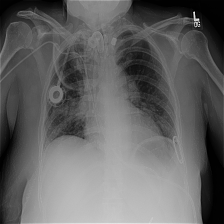

In [17]:
import requests
from PIL import Image
from io import BytesIO

# Pick one image from our training dataset
sample_filename = small_train_df.iloc[0]['Image Index']

# Build its download address
url = (
    'https://nih-chest-x-rays.s3.us-east-2.amazonaws.com/'
    'images_224x224/' + sample_filename
)

response = requests.get(url, timeout=30)

print("Filename:", sample_filename)
print("HTTP status:", response.status_code)

if response.status_code == 200:
    img = Image.open(BytesIO(response.content))
    print("Image dimensions:", img.size)
    print("Image size:", len(response.content) / 1024, "KB")
    display(img)
else:
    print("Image could not be downloaded.")

In [18]:
import os
import time
import requests
import pandas as pd

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.notebook import tqdm

# Folder for downloaded images
image_dir = os.path.join(subset_path, 'images')
os.makedirs(image_dir, exist_ok=True)

# Combine filenames from all three datasets
all_filenames = pd.concat([
    small_train_df['Image Index'],
    small_val_df['Image Index'],
    small_test_df['Image Index']
]).drop_duplicates().tolist()

print("Total unique images to download:", len(all_filenames))


# Function to download one image
def download_image(filename):

    file_path = os.path.join(image_dir, filename)

    # Skip if already downloaded
    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        return filename, None

    url = (
        'https://nih-chest-x-rays.s3.us-east-2.amazonaws.com/'
        'images_224x224/' + filename
    )

    for attempt in range(3):
        try:
            response = requests.get(url, timeout=30)

            if response.status_code == 200 and response.content:
                with open(file_path, 'wb') as f:
                    f.write(response.content)

                return filename, None

            error = f"HTTP {response.status_code}"

        except Exception as e:
            error = str(e)

        time.sleep(attempt + 1)

    return filename, error


# Download images using 8 workers
failed = []

with ThreadPoolExecutor(max_workers=8) as executor:

    futures = [
        executor.submit(download_image, filename)
        for filename in all_filenames
    ]

    for future in tqdm(as_completed(futures), total=len(futures)):
        filename, error = future.result()

        if error is not None:
            failed.append({
                'Image Index': filename,
                'Error': error
            })


# Save failed download records
failed_df = pd.DataFrame(failed)

if len(failed_df) > 0:
    failed_df.to_csv(
        os.path.join(subset_path, 'failed_downloads.csv'),
        index=False
    )

print("\nDownload process finished!")
print("Total images:", len(all_filenames))
print("Failed downloads:", len(failed_df))
print("Downloaded or already available:",
      len(all_filenames) - len(failed_df))

Total unique images to download: 17201


  0%|          | 0/17201 [00:00<?, ?it/s]


Download process finished!
Total images: 17201
Failed downloads: 0
Downloaded or already available: 17201


Expected images: 17201
Images downloaded: 17201
Missing images: 0

Sample image dimensions: (224, 224)
Image format: PNG


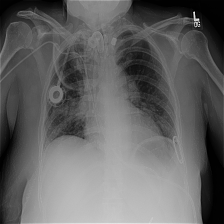

In [4]:
import os
import pandas as pd
from PIL import Image

# Load our three CSV files
subset_path = '/content/drive/MyDrive/Chest_Xray_Project/Classification_Data/Small_Dataset'
image_dir = os.path.join(subset_path, 'images')

train_df = pd.read_csv(os.path.join(subset_path, 'train.csv'))
val_df = pd.read_csv(os.path.join(subset_path, 'validation.csv'))
test_df = pd.read_csv(os.path.join(subset_path, 'test.csv'))

# Collect all expected filenames
all_filenames = pd.concat([
    train_df['Image Index'],
    val_df['Image Index'],
    test_df['Image Index']
]).unique()

# Check which files are missing
missing = [
    filename for filename in all_filenames
    if not os.path.exists(os.path.join(image_dir, filename))
]

print("Expected images:", len(all_filenames))
print("Images downloaded:", len(all_filenames) - len(missing))
print("Missing images:", len(missing))

# Inspect one downloaded image
sample_path = os.path.join(image_dir, all_filenames[0])

img = Image.open(sample_path)

print("\nSample image dimensions:", img.size)
print("Image format:", img.format)
display(img)

In [5]:
import os

subset_path = '/content/drive/MyDrive/Chest_Xray_Project/Classification_Data/Small_Dataset'

print(os.listdir(subset_path))

['train.csv', 'validation.csv', 'test.csv', 'images']


In [6]:
import pandas as pd
import os

subset_path = '/content/drive/MyDrive/Chest_Xray_Project/Classification_Data/Small_Dataset'
image_dir = os.path.join(subset_path, 'images')

train_df = pd.read_csv(os.path.join(subset_path, 'train.csv'))
val_df = pd.read_csv(os.path.join(subset_path, 'validation.csv'))
test_df = pd.read_csv(os.path.join(subset_path, 'test.csv'))

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining data preview:")
display(train_df.head())

Training images: 11007
Validation images: 2843
Testing images: 3351

Training data preview:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00010790_032.png,No Finding,32,10790,55,F,AP,2500,2048,0.168,0.168
1,00006806_001.png,Cardiomegaly,1,6806,48,F,PA,2048,2500,0.171,0.171
2,00018067_000.png,No Finding,0,18067,25,F,PA,2502,2991,0.143,0.143
3,00000127_007.png,Pleural Effusion,7,127,56,F,AP,2500,2048,0.168,0.168
4,00016780_003.png,Pleural Effusion,3,16780,36,F,PA,2992,2991,0.143,0.143


In [7]:
print(train_df['Finding Labels'].value_counts())

Finding Labels
No Finding          4000
Atelectasis         2597
Pleural Effusion    2538
Consolidation        812
Cardiomegaly         665
Edema                395
Name: count, dtype: int64


In [8]:
class_names = [
    'Atelectasis',
    'Cardiomegaly',
    'Consolidation',
    'Edema',
    'No Finding',
    'Pleural Effusion'
]

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

train_df['label'] = train_df['Finding Labels'].map(class_to_index)
val_df['label'] = val_df['Finding Labels'].map(class_to_index)
test_df['label'] = test_df['Finding Labels'].map(class_to_index)

print(train_df[['Finding Labels', 'label']].head())

     Finding Labels  label
0        No Finding      4
1      Cardiomegaly      1
2        No Finding      4
3  Pleural Effusion      5
4  Pleural Effusion      5


In [9]:
print("CSV filename example:")
print(train_df['Image Index'].iloc[0])

print("\nImage file exists:")
filename = train_df['Image Index'].iloc[0]
print(os.path.exists(os.path.join(image_dir, filename)))

CSV filename example:
00010790_032.png

Image file exists:
True


In [10]:
import tensorflow as tf
import numpy as np

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
# DenseNet121 preprocessing function
preprocess_input = tf.keras.applications.densenet.preprocess_input

# Function to load and prepare one image
def load_image(image_path, label):

    # Read image
    image = tf.io.read_file(image_path)

    # Decode PNG and convert grayscale to 3 channels
    image = tf.io.decode_png(image, channels=3)

    # Ensure image dimensions are 224 x 224
    image = tf.image.resize(image, [224, 224])

    # Apply DenseNet121 preprocessing
    image = preprocess_input(image)

    return image, label


# Function to create a dataset
def create_dataset(dataframe, training=False):

    image_paths = [
        os.path.join(image_dir, filename)
        for filename in dataframe['Image Index']
    ]

    labels = dataframe['label'].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(buffer_size=len(dataframe))

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create all three datasets
train_dataset = create_dataset(train_df, training=True)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("Datasets created successfully!")


Datasets created successfully!


In [12]:
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>


In [13]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models

base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Initially freeze pretrained layers
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         6,150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,043,654 (26.87 MB)

 Trainable params: 6,150 (24.02 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(6),
    y=train_df['label'].values
)

class_weights_dict = {
    i: weight for i, weight in enumerate(class_weights)
}

print(class_weights_dict)

{0: np.float64(0.7063919907585676), 1: np.float64(2.7586466165413532), 2: np.float64(2.2592364532019706), 3: np.float64(4.644303797468354), 4: np.float64(0.458625), 5: np.float64(0.7228132387706856)}


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        '/content/drive/MyDrive/Chest_Xray_Project/Models/densenet121_best.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights_dict,
    callbacks=callbacks
)

Epoch 1/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 1725s 5s/step - accuracy: 0.2636 - loss: 1.8754 - val_accuracy: 0.2490 - val_loss: 1.7149
Epoch 2/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 54s 157ms/step - accuracy: 0.3199 - loss: 1.6662 - val_accuracy: 0.4541 - val_loss: 1.3918
Epoch 3/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 78s 146ms/step - accuracy: 0.3299 - loss: 1.6184 - val_accuracy: 0.2958 - val_loss: 1.7083
Epoch 4/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 52s 150ms/step - accuracy: 0.3404 - loss: 1.5832 - val_accuracy: 0.3778 - val_loss: 1.5291
Epoch 5/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 59s 171ms/step - accuracy: 0.3564 - loss: 1.5439 - val_accuracy: 0.3813 - val_loss: 1.4933


In [16]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

105/105 ━━━━━━━━━━━━━━━━━━━━ 428s 4s/step - accuracy: 0.4232 - loss: 1.4279
Test Loss: 1.4278837442398071
Test Accuracy: 0.423157274723053
